#### Github: 
https://github.com/Munkhzaya-pom/statistic-sep-26/tree/main/CA2_stats_sep_26
#### Video: 
?

## Introduction

Cycling is becoming more popular in modern cities, and I believe this is a positive change because bicycles are environmentally friendly, affordable and can help reduce traffic congestion.

I chose the Seoul Bike Sharing Demand dataset because I am interested in whether a similar business could work in Mongolia. Mongolia has four distinct seasons, and traffic congestion is a major problem in Ulaanbaatar. Although this dataset is from South Korea, I wanted to explore how weather conditions, especially colder temperatures, are related to bicycle rental demand.

The dataset was obtained from the UCI Machine Learning Repository and contains 8,760 observations and 14 variables, including temperature, humidity, rainfall, snowfall, seasons and bicycle rental counts. In this study, I will use descriptive statistics, visualisations, confidence intervals and hypothesis testing to understand how weather and seasonal changes are related to bicycle rentals.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("SeoulBikeData.csv", encoding="cp1252")
df.head()

,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Date                       8760 non-null   str    
 1   Rented Bike Count          8760 non-null   int64  
 2   Hour                       8760 non-null   int64  
 3   Temperature(°C)            8760 non-null   float64
 4   Humidity(%)                8760 non-null   int64  
 5   Wind speed (m/s)           8760 non-null   float64
 6   Visibility (10m)           8760 non-null   int64  
 7   Dew point temperature(°C)  8760 non-null   float64
 8   Solar Radiation (MJ/m2)    8760 non-null   float64
 9   Rainfall(mm)               8760 non-null   float64
 10  Snowfall (cm)              8760 non-null   float64
 11  Seasons                    8760 non-null   str    
 12  Holiday                    8760 non-null   str    
 13  Functioning Day            8760 non-null   str    
dtypes: 

In [4]:
df.describe()

,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm)
count,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000
mean,704.602055,11.500000,12.882922,58.226256,1.724909,1436.825799,4.073813,0.569111,0.148687,0.075068
std,644.997468,6.922582,11.944825,20.362413,1.036300,608.298712,13.060369,0.868746,1.128193,0.436746
min,0.000000,0.000000,-17.800000,0.000000,0.000000,27.000000,-30.600000,0.000000,0.000000,0.000000
25%,191.000000,5.750000,3.500000,42.000000,0.900000,940.000000,-4.700000,0.000000,0.000000,0.000000
50%,504.500000,11.500000,13.700000,57.000000,1.500000,1698.000000,5.100000,0.010000,0.000000,0.000000
75%,1065.250000,17.250000,22.500000,74.000000,2.300000,2000.000000,14.800000,0.930000,0.000000,0.000000
max,3556.000000,23.000000,39.400000,98.000000,7.400000,2000.000000,27.200000,3.520000,35.000000,8.800000


In [5]:
df.describe(include=["object", "category"])

/var/folders/lj/_7rtgkcn65s9bglk6kjj2rr00000gn/T/ipykernel_57560/2615815932.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include=["object", "category"])


,Date,Seasons,Holiday,Functioning Day
count,8760,8760,8760,8760
unique,365,4,2,2
top,01/12/2017,Spring,No Holiday,Yes
freq,24,2208,8328,8465


In [6]:
df.shape

(8760, 14)

In [7]:
df.isnull().sum()

Date                         0
Rented Bike Count            0
Hour                         0
Temperature(°C)              0
Humidity(%)                  0
Wind speed (m/s)             0
Visibility (10m)             0
Dew point temperature(°C)    0
Solar Radiation (MJ/m2)      0
Rainfall(mm)                 0
Snowfall (cm)                0
Seasons                      0
Holiday                      0
Functioning Day              0
dtype: int64

In [8]:
df.duplicated()

0       False
1       False
2       False
3       False
4       False
        ...  
8755    False
8756    False
8757    False
8758    False
8759    False
Length: 8760, dtype: bool

In [9]:
#Check the target variable

df["Rented Bike Count"].head(10)

0    254
1    204
2    173
3    107
4     78
5    100
6    181
7    460
8    930
9    490
Name: Rented Bike Count, dtype: int64

In [10]:
#Summary statistics of bicycle rentals

df["Rented Bike Count"].describe()

count    8760.000000
mean      704.602055
std       644.997468
min         0.000000
25%       191.000000
50%       504.500000
75%      1065.250000
max      3556.000000
Name: Rented Bike Count, dtype: float64

In [11]:
#Count hours with zero bicycle rentals

(df["Rented Bike Count"] == 0).sum()

np.int64(295)

In [12]:
#Check operating and non-operating hours

df["Functioning Day"].value_counts()

Functioning Day
Yes    8465
No      295
Name: count, dtype: int64

In [13]:
#Compare rental counts by functioning status

df.groupby("Functioning Day")["Rented Bike Count"].agg(["count", "mean", "median", "min", "max"])

,count,mean,median,min,max
Functioning Day,,,,,
No,295,0.000000,0.0,0,0
Yes,8465,729.156999,542.0,2,3556


In [14]:
#Select non-functioning hours

df_inactive = df[df["Functioning Day"] == "No"].copy()

#Count non-functioning hours for each date
df_inactive.groupby("Date").size().sort_values(ascending = False)

Date
02/10/2018    24
03/11/2018    24
04/10/2018    24
06/11/2018    24
09/10/2018    24
09/11/2018    24
10/05/2018    24
11/04/2018    24
18/09/2018    24
19/09/2018    24
28/09/2018    24
30/09/2018    24
06/10/2018     7
dtype: int64

In [15]:
#Check non-functioning hours by season

df_inactive["Seasons"].value_counts()

Seasons
Autumn    247
Spring     48
Name: count, dtype: int64

In [16]:
#Weather conditions during non-functioning hours

df_inactive[["Temperature(°C)", "Rainfall(mm)", "Snowfall (cm)"]].describe()

,Temperature(°C),Rainfall(mm),Snowfall (cm)
count,295.000000,295.000000,295.0
mean,16.092881,0.136271,0.0
std,4.690414,1.203795,0.0
min,5.200000,0.000000,0.0
25%,12.300000,0.000000,0.0
50%,16.300000,0.000000,0.0
75%,19.350000,0.000000,0.0
max,26.500000,18.000000,0.0


In [17]:
#Create a dataset containing only functioning hours

df_active = df[df["Functioning Day"] == "Yes"].copy()

print("Original observations:", len(df))
print("Active observations:", len(df_active))

Original observations: 8760
Active observations: 8465


#### Functioning Day Analysis

The results show that the bike rental service was not operating for 295 hours across 13 dates, mainly in autumn (247 hours) and spring (48 hours). The average temperature during these periods was 16.09°C, ranging from 5.2°C to 26.5°C. No snowfall was recorded, and most hours had no rainfall. However, the exact reasons for service interruptions are unknown.

I excluded these hours from the main analysis because zero rentals during non-functioning periods do not reflect actual customer demand. I kept the original dataset as it was, but I will also discuss how removing these hours might affect my results.

## Descriptive statistics for bicycle rentals

In [18]:
#Descriptive statistics for bicycle rentals

df_active["Rented Bike Count"].describe()

count    8465.000000
mean      729.156999
std       642.351166
min         2.000000
25%       214.000000
50%       542.000000
75%      1084.000000
max      3556.000000
Name: Rented Bike Count, dtype: float64

Here, we can see that the mean is higher than the median, which suggests that the distribution is right-skewed.

In [20]:
#Check skewness of bicycle rental counts

df_active["Rented Bike Count"].skew()

np.float64(1.1397000550865906)

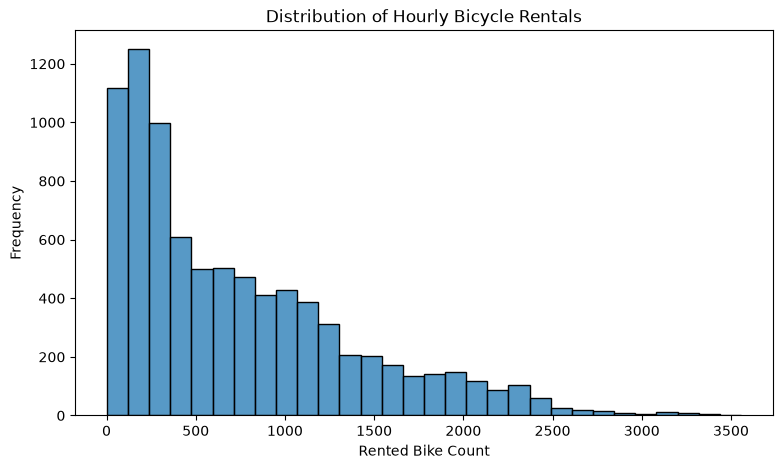

In [21]:
# Histogram of bicycle rental counts

plt.figure(figsize=(9, 5))

sns.histplot(data = df_active, x = "Rented Bike Count", bins = 30)

plt.title("Distribution of Hourly Bicycle Rentals")
plt.xlabel("Rented Bike Count")
plt.ylabel("Frequency")

plt.show()


In this graph, the X-axis shows the number of rented bikes, while the Y-axis shows the frequency. For example, a frequency of 1,200 for the range of 100–250 bikes means that between 100 and 250 bikes were rented in each of approximately 1,200 different hours.

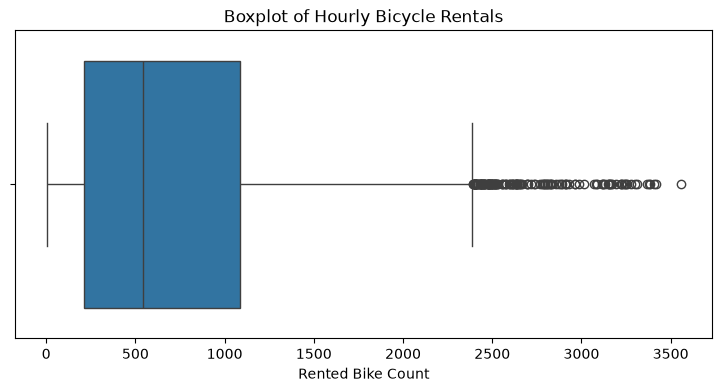

In [22]:
#Boxplot of hourly bicycle rentals

plt.figure(figsize = (9, 4))

sns.boxplot(data = df_active, x = "Rented Bike Count")

plt.title("Boxplot of Hourly Bicycle Rentals")
plt.xlabel("Rented Bike Count")

plt.show()

In [23]:
#Calculate the IQR and identify potential outliers

Q1 = df_active["Rented Bike Count"].quantile(0.25)
Q3 = df_active["Rented Bike Count"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df_active[
    (df_active["Rented Bike Count"] < lower_bound) |
    (df_active["Rented Bike Count"] > upper_bound)]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Number of potential outliers:", len(outliers))

Q1: 214.0
Q3: 1084.0
IQR: 870.0
Lower bound: -1091.0
Upper bound: 2389.0
Number of potential outliers: 152


#### Boxplot and IQR Analysis

The boxplot shows that bicycle rental counts are right-skewed, with several high values on the right side. Using the IQR method, I found 152 potential outliers above the upper bound of 2,389, which is about 1.8% of the data. No lower outliers were found.

I decided to keep these values because they may represent periods of high rental demand rather than errors. Removing them could affect the results of my analysis.

In [24]:
#Count potential outliers by season

outliers["Seasons"].value_counts()

Seasons
Summer    85
Autumn    35
Spring    32
Name: count, dtype: int64

In [25]:
#Temperature during high rental hours

outliers["Temperature(°C)"].describe()

count    152.000000
mean      24.307237
std        4.547572
min       12.200000
25%       22.075000
50%       24.750000
75%       27.000000
max       35.400000
Name: Temperature(°C), dtype: float64

In [26]:
#Check hours with high bicycle rentals

outliers["Hour"].value_counts().sort_index()

Hour
8      4
16     2
17     7
18    86
19    34
20    15
21     4
Name: count, dtype: int64

#### Analysis of High Rental Counts

Most of the 152 potential outliers occurred in summer (85), with none in winter. The average temperature was 24.31°C, but high rentals were also recorded at 12.2°C. Most occurred between 18:00 and 20:00, possibly when people were returning from work.

These results suggest that very high rental demand is more common in warmer weather and evening hours. I decided to keep these values because they may reflect real demand rather than errors.

### Seasonal Analysis of Bicycle Rentals

In [27]:
#Descriptive statistics for each season

df_active.groupby("Seasons")["Rented Bike Count"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
Seasons,,,,,,,,
Autumn,1937.0,924.11,617.55,2.0,427.00,856.0,1271.0,3298.0
Spring,2160.0,746.25,618.67,2.0,225.00,599.0,1118.0,3251.0
Summer,2208.0,1034.07,690.24,9.0,526.75,905.5,1442.5,3556.0
Winter,2160.0,225.54,150.37,3.0,110.00,203.0,305.0,937.0


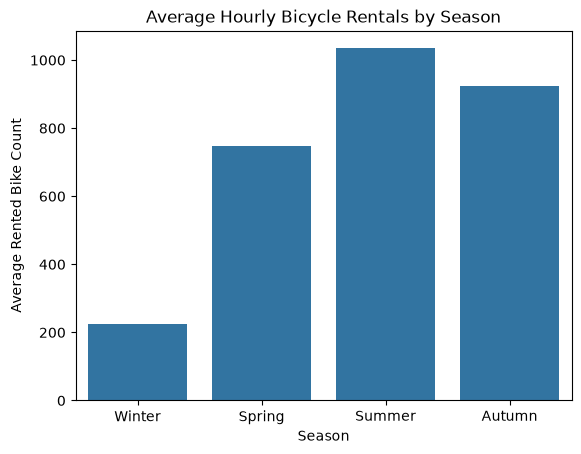

In [28]:
# Average bicycle rentals by season

season_order = ["Winter", "Spring", "Summer", "Autumn"]

sns.barplot(
    data = df_active,
    x = "Seasons",
    y = "Rented Bike Count",
    order = season_order,
    errorbar = None)

plt.title("Average Hourly Bicycle Rentals by Season")
plt.xlabel("Season")
plt.ylabel("Average Rented Bike Count")
plt.show()

Here, we can see that bicycle rental demand varies considerably across different seasons.